In [1]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make src importable
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_dreaddit

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\sudha\Downloads\mental_health_prediction


In [2]:
train_df, test_df = load_dreaddit()

print("Training shape:", train_df.shape)
print("Testing shape :", test_df.shape)

Training shape: (2838, 116)
Testing shape : (715, 116)


In [3]:
print("Columns:")
print(train_df.columns.tolist())

Columns:
['subreddit', 'post_id', 'sentence_range', 'text', 'id', 'label', 'confidence', 'social_timestamp', 'social_karma', 'syntax_ari', 'lex_liwc_WC', 'lex_liwc_Analytic', 'lex_liwc_Clout', 'lex_liwc_Authentic', 'lex_liwc_Tone', 'lex_liwc_WPS', 'lex_liwc_Sixltr', 'lex_liwc_Dic', 'lex_liwc_function', 'lex_liwc_pronoun', 'lex_liwc_ppron', 'lex_liwc_i', 'lex_liwc_we', 'lex_liwc_you', 'lex_liwc_shehe', 'lex_liwc_they', 'lex_liwc_ipron', 'lex_liwc_article', 'lex_liwc_prep', 'lex_liwc_auxverb', 'lex_liwc_adverb', 'lex_liwc_conj', 'lex_liwc_negate', 'lex_liwc_verb', 'lex_liwc_adj', 'lex_liwc_compare', 'lex_liwc_interrog', 'lex_liwc_number', 'lex_liwc_quant', 'lex_liwc_affect', 'lex_liwc_posemo', 'lex_liwc_negemo', 'lex_liwc_anx', 'lex_liwc_anger', 'lex_liwc_sad', 'lex_liwc_social', 'lex_liwc_family', 'lex_liwc_friend', 'lex_liwc_female', 'lex_liwc_male', 'lex_liwc_cogproc', 'lex_liwc_insight', 'lex_liwc_cause', 'lex_liwc_discrep', 'lex_liwc_tentat', 'lex_liwc_certain', 'lex_liwc_differ', '

In [4]:
train_df.head()


,subreddit,post_id,sentence_range,text,id,label,confidence,social_timestamp,social_karma,syntax_ari,...,lex_dal_min_pleasantness,lex_dal_min_activation,lex_dal_min_imagery,lex_dal_avg_activation,lex_dal_avg_imagery,lex_dal_avg_pleasantness,social_upvote_ratio,social_num_comments,syntax_fk_grade,sentiment
0,ptsd,8601tu,"(15, 20)","He said he had not felt that way before, sugge...",33181,1,0.8,1521614353,5,1.806818,...,1.000,1.1250,1.0,1.77000,1.52211,1.89556,0.86,1,3.253573,-0.002742
1,assistance,8lbrx9,"(0, 5)","Hey there r/assistance, Not sure if this is th...",2606,0,1.0,1527009817,4,9.429737,...,1.125,1.0000,1.0,1.69586,1.62045,1.88919,0.65,2,8.828316,0.292857
2,ptsd,9ch1zh,"(15, 20)",My mom then hit me with the newspaper and it s...,38816,1,0.8,1535935605,2,7.769821,...,1.000,1.1429,1.0,1.83088,1.58108,1.85828,0.67,0,7.841667,0.011894
3,relationships,7rorpp,"[5, 10]","until i met my new boyfriend, he is amazing, h...",239,1,0.6,1516429555,0,2.667798,...,1.000,1.1250,1.0,1.75356,1.52114,1.98848,0.50,5,4.104027,0.141671
4,survivorsofabuse,9p2gbc,"[0, 5]",October is Domestic Violence Awareness Month a...,1421,1,0.8,1539809005,24,7.554238,...,1.000,1.1250,1.0,1.77644,1.64872,1.81456,1.00,1,7.910952,-0.204167


In [5]:
print("Missing values in training data:\n")
print(train_df.isnull().sum())

Missing values in training data:

subreddit                   0
post_id                     0
sentence_range              0
text                        0
id                          0
                           ..
lex_dal_avg_pleasantness    0
social_upvote_ratio         0
social_num_comments         0
syntax_fk_grade             0
sentiment                   0
Length: 116, dtype: int64


In [7]:
duplicate_count = train_df["text"].duplicated().sum()

print("Duplicate text entries:", duplicate_count)

Duplicate text entries: 18


In [8]:
label_counts = train_df["label"].value_counts().sort_index()

print(label_counts)

label
0    1350
1    1488
Name: count, dtype: int64


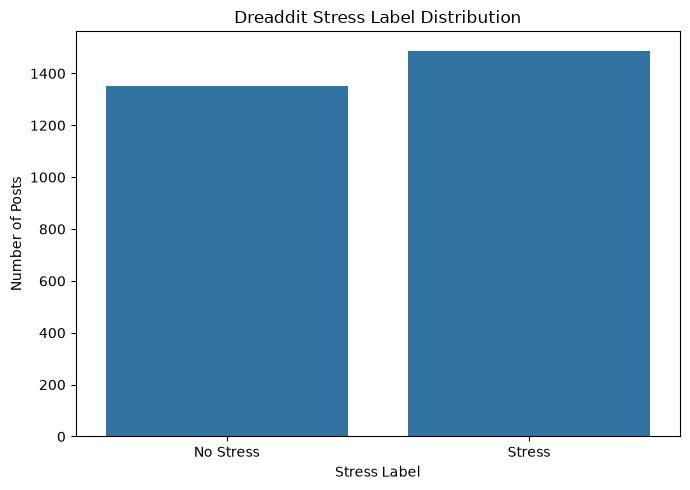

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="label"
)

plt.title("Dreaddit Stress Label Distribution")
plt.xlabel("Stress Label")
plt.ylabel("Number of Posts")

plt.xticks(
    [0, 1],
    ["No Stress", "Stress"]
)

plt.tight_layout()
plt.show()

In [10]:
train_df["word_count"] = train_df["text"].apply(
    lambda x: len(str(x).split())
)

print(train_df["word_count"].describe())

count    2838.000000
mean       85.669838
std        32.292305
min         1.000000
25%        65.000000
50%        80.000000
75%       101.000000
max       310.000000
Name: word_count, dtype: float64


C:\Users\sudha\AppData\Local\Temp\ipykernel_16532\181182673.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_df["word_count"] = train_df["text"].apply(


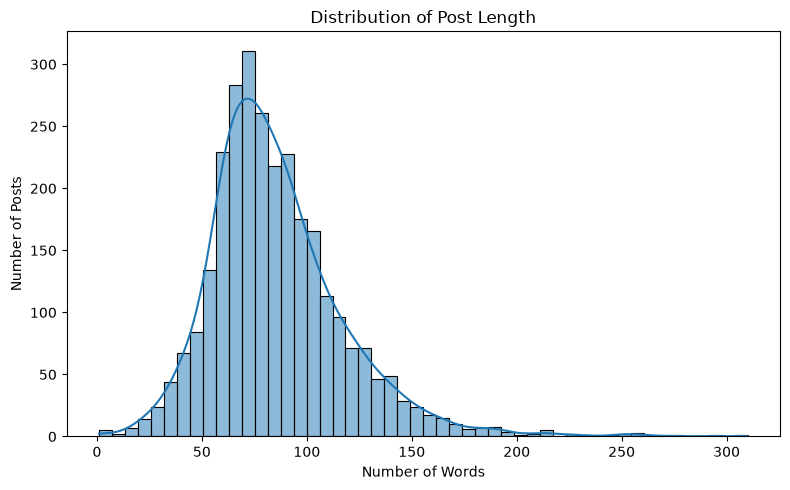

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(
    train_df["word_count"],
    bins=50,
    kde=True
)

plt.title("Distribution of Post Length")
plt.xlabel("Number of Words")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

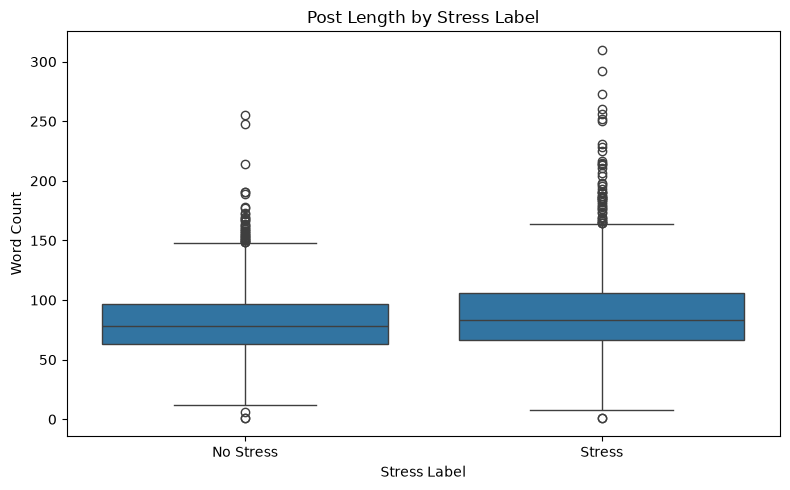

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x="label",
    y="word_count"
)

plt.title("Post Length by Stress Label")
plt.xlabel("Stress Label")
plt.ylabel("Word Count")

plt.xticks(
    [0, 1],
    ["No Stress", "Stress"]
)

plt.tight_layout()
plt.show()

In [13]:
if "subreddit" in train_df.columns:

    subreddit_counts = (
        train_df["subreddit"]
        .value_counts()
        .head(15)
    )

    print(subreddit_counts)

subreddit
ptsd                584
relationships       552
anxiety             503
domesticviolence    316
assistance          289
survivorsofabuse    245
homeless            168
almosthomeless       80
stress               64
food_pantry          37
Name: count, dtype: int64


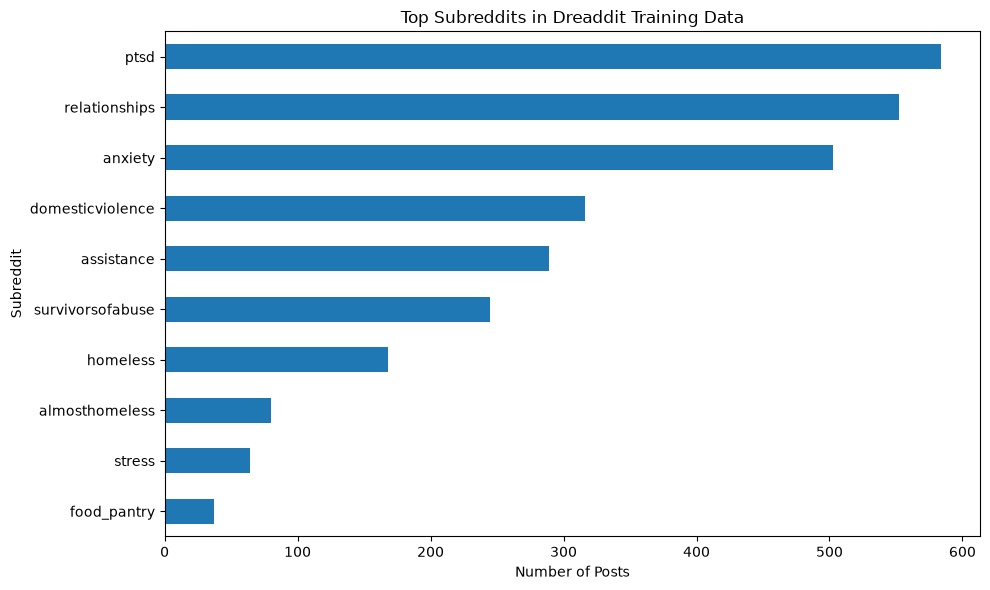

In [14]:
if "subreddit" in train_df.columns:

    plt.figure(figsize=(10, 6))

    subreddit_counts.sort_values().plot(
        kind="barh"
    )

    plt.title("Top Subreddits in Dreaddit Training Data")
    plt.xlabel("Number of Posts")
    plt.ylabel("Subreddit")

    plt.tight_layout()
    plt.show()

In [15]:
print("========== NO STRESS EXAMPLES ==========\n")

for text in train_df.loc[
    train_df["label"] == 0, "text"
].head(3):
    print(text)
    print("\n" + "-" * 80 + "\n")


print("========== STRESS EXAMPLES ==========\n")

for text in train_df.loc[
    train_df["label"] == 1, "text"
].head(3):
    print(text)
    print("\n" + "-" * 80 + "\n")

========== NO STRESS EXAMPLES ==========

Hey there r/assistance, Not sure if this is the right place to post this.. but here goes =) I'm currently a student intern at Sandia National Labs and working on a survey to help improve our marketing outreach efforts at the many schools we recruit at around the country. We're looking for current undergrad/grad STEM students so if you're a STEM student or know STEM students, I would greatly appreciate if you can help take or pass along this short survey. As a thank you, everyone who helps take the survey will be entered in to a drawing for chance to win one of three $50 Amazon gcs.

--------------------------------------------------------------------------------

It was a big company so luckily I didn't have to see him all the time, but when I did, he again acted as though I didn't exist. I tried to talk to him and update him on the pregnancy, and ask him to be involved for our child's sake, and he literally stared right through me without sayi